In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [7]:
#adata = sc.read("/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi.h5ad")
adata=sc.read("write/pool_scvi_v2.h5ad")

In [8]:
adata_d0 = adata[adata.obs['HSC_days']==0]
adata_d18 = adata[adata.obs['HSC_days']==18]

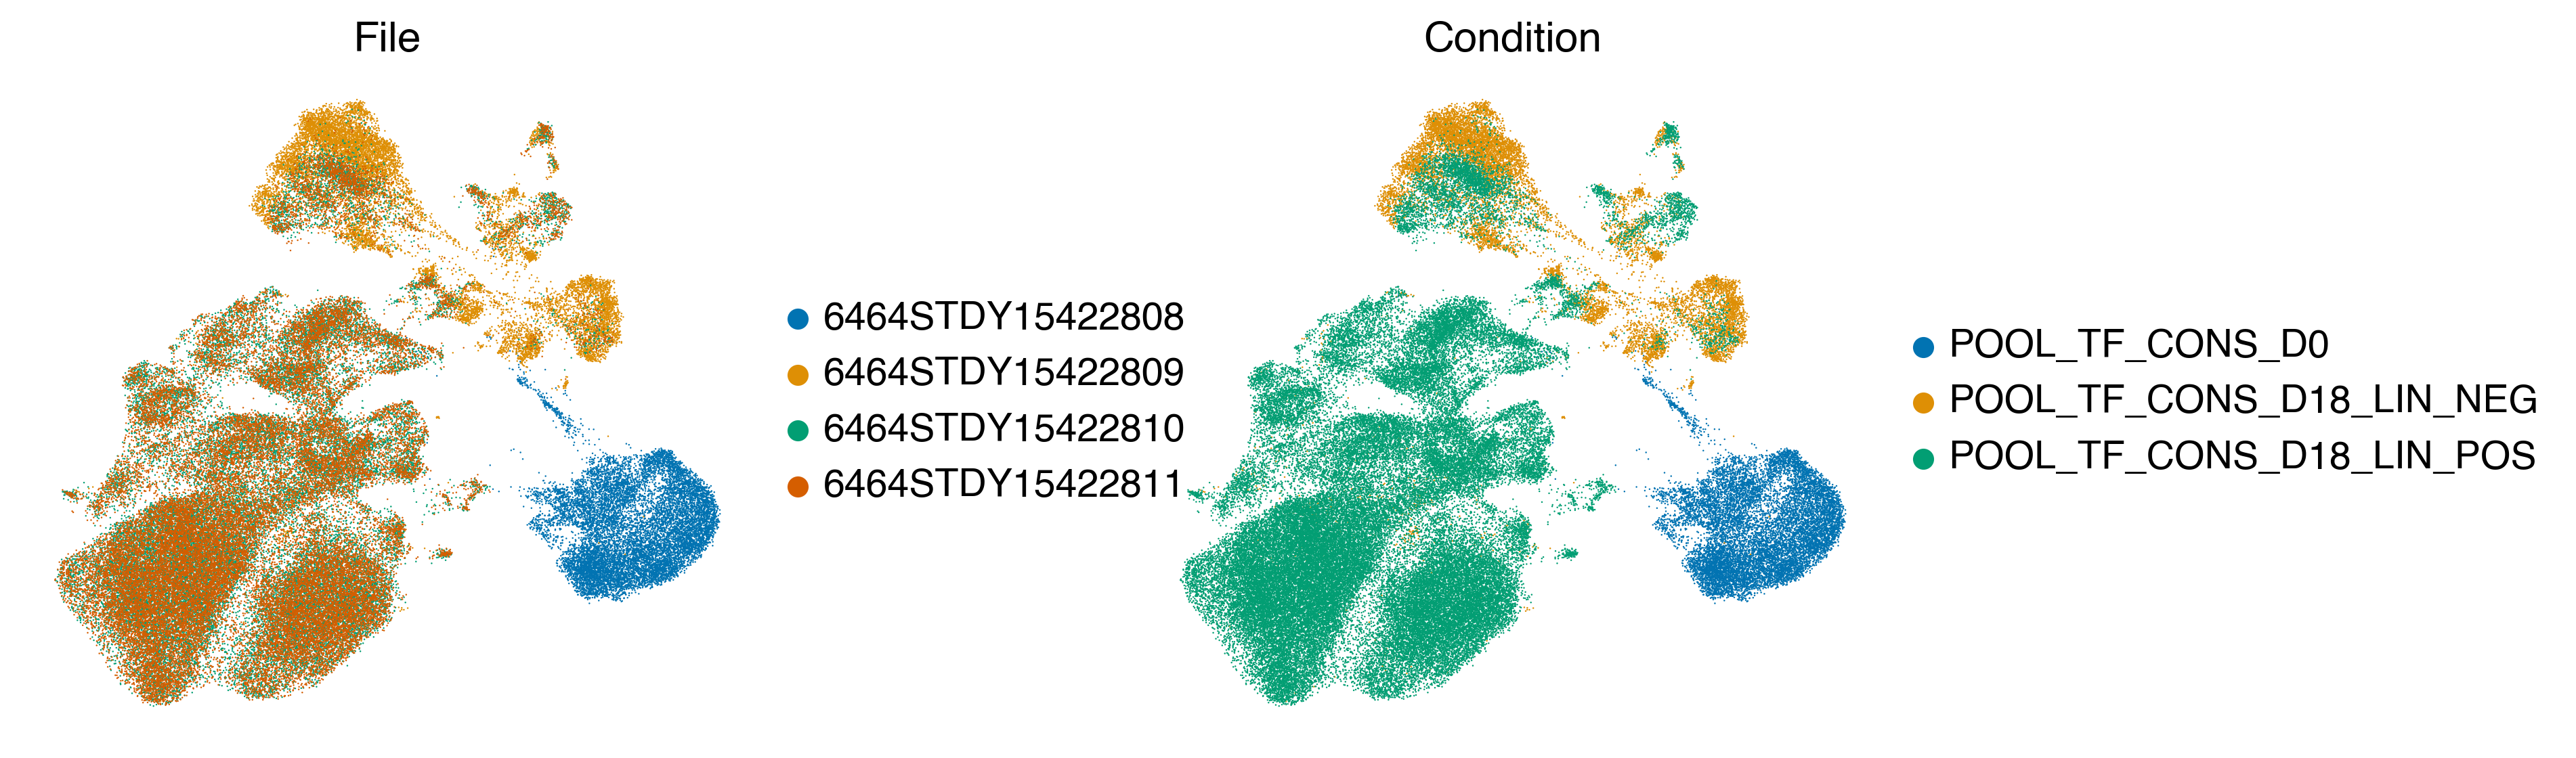

In [12]:
plt.rcParams["figure.figsize"] = [4,4]
sc.pl.umap(
    adata,
    color=["file",'sanger_sample_ID'],
    title = ['File','Condition'],
    frameon=False, wspace=0.4,
    ncols=2,
    save='pool_file_sampleid.pdf',
)

# Demonstrate that TF has worked

## Is TF expression higher in cells with exogenous TF called

In [13]:
tf_list = [tf for tf in adata.obs['TF_calling'].cat.categories if tf in adata.var_names]

In [14]:
len(tf_list) # only MULTIHIT is not inside 

1377

In [16]:
df_d0 = pd.DataFrame(index = tf_list, columns = ['mean_exp_called','mean_exp_others','exp_ratio'])
df_d18 = pd.DataFrame(index = tf_list, columns = ['mean_exp_called','mean_exp_others','exp_ratio'])

In [17]:
X_d0 = adata_d0.X.toarray()
X_d18 = adata_d18.X.toarray()

In [18]:
for tf in tf_list:
    idx = adata.var_names.get_loc(tf)
    select1 = adata_d0.obs['TF_calling'] == tf

    if np.sum(select1) > 9: ### Only keep TFs with at least 10 cells called
        df_d0.loc[tf, 'mean_exp_called'] = np.mean(X_d0[select1.values, idx])
        df_d0.loc[tf, 'mean_exp_others'] = np.mean(X_d0[~select1.values, idx])
        
    select2 = adata_d18.obs['TF_calling'] == tf
    if np.sum(select2) > 9: ### Only keep TFs with at least 10 cells called
        df_d18.loc[tf, 'mean_exp_called'] = np.mean(X_d18[select2.values, idx])
        df_d18.loc[tf, 'mean_exp_others'] = np.mean(X_d18[~select2.values, idx])

In [19]:
df_d0['exp_ratio'] = df_d0['mean_exp_called'] / df_d0['mean_exp_others']
df_d18['exp_ratio'] = df_d18['mean_exp_called'] / df_d18['mean_exp_others']

In [20]:
df_d0.to_csv('csv/barcode_exp_d0.csv')
df_d18.to_csv('csv/barcode_exp_d18.csv')

In [21]:
df_d0 = pd.read_csv('csv/barcode_exp_d0.csv', index_col=0)
df_d18 = pd.read_csv('csv/barcode_exp_d18.csv', index_col=0)

In [22]:
# Add suffixes to column names
df_d0_renamed = df_d0.add_suffix('_d0')
df_d18_renamed = df_d18.add_suffix('_d18')

# Concatenate by rows
df_combined = pd.concat([df_d0_renamed, df_d18_renamed], axis=1, ignore_index=False)

### separate D0 and 18; link called and others for the same TF

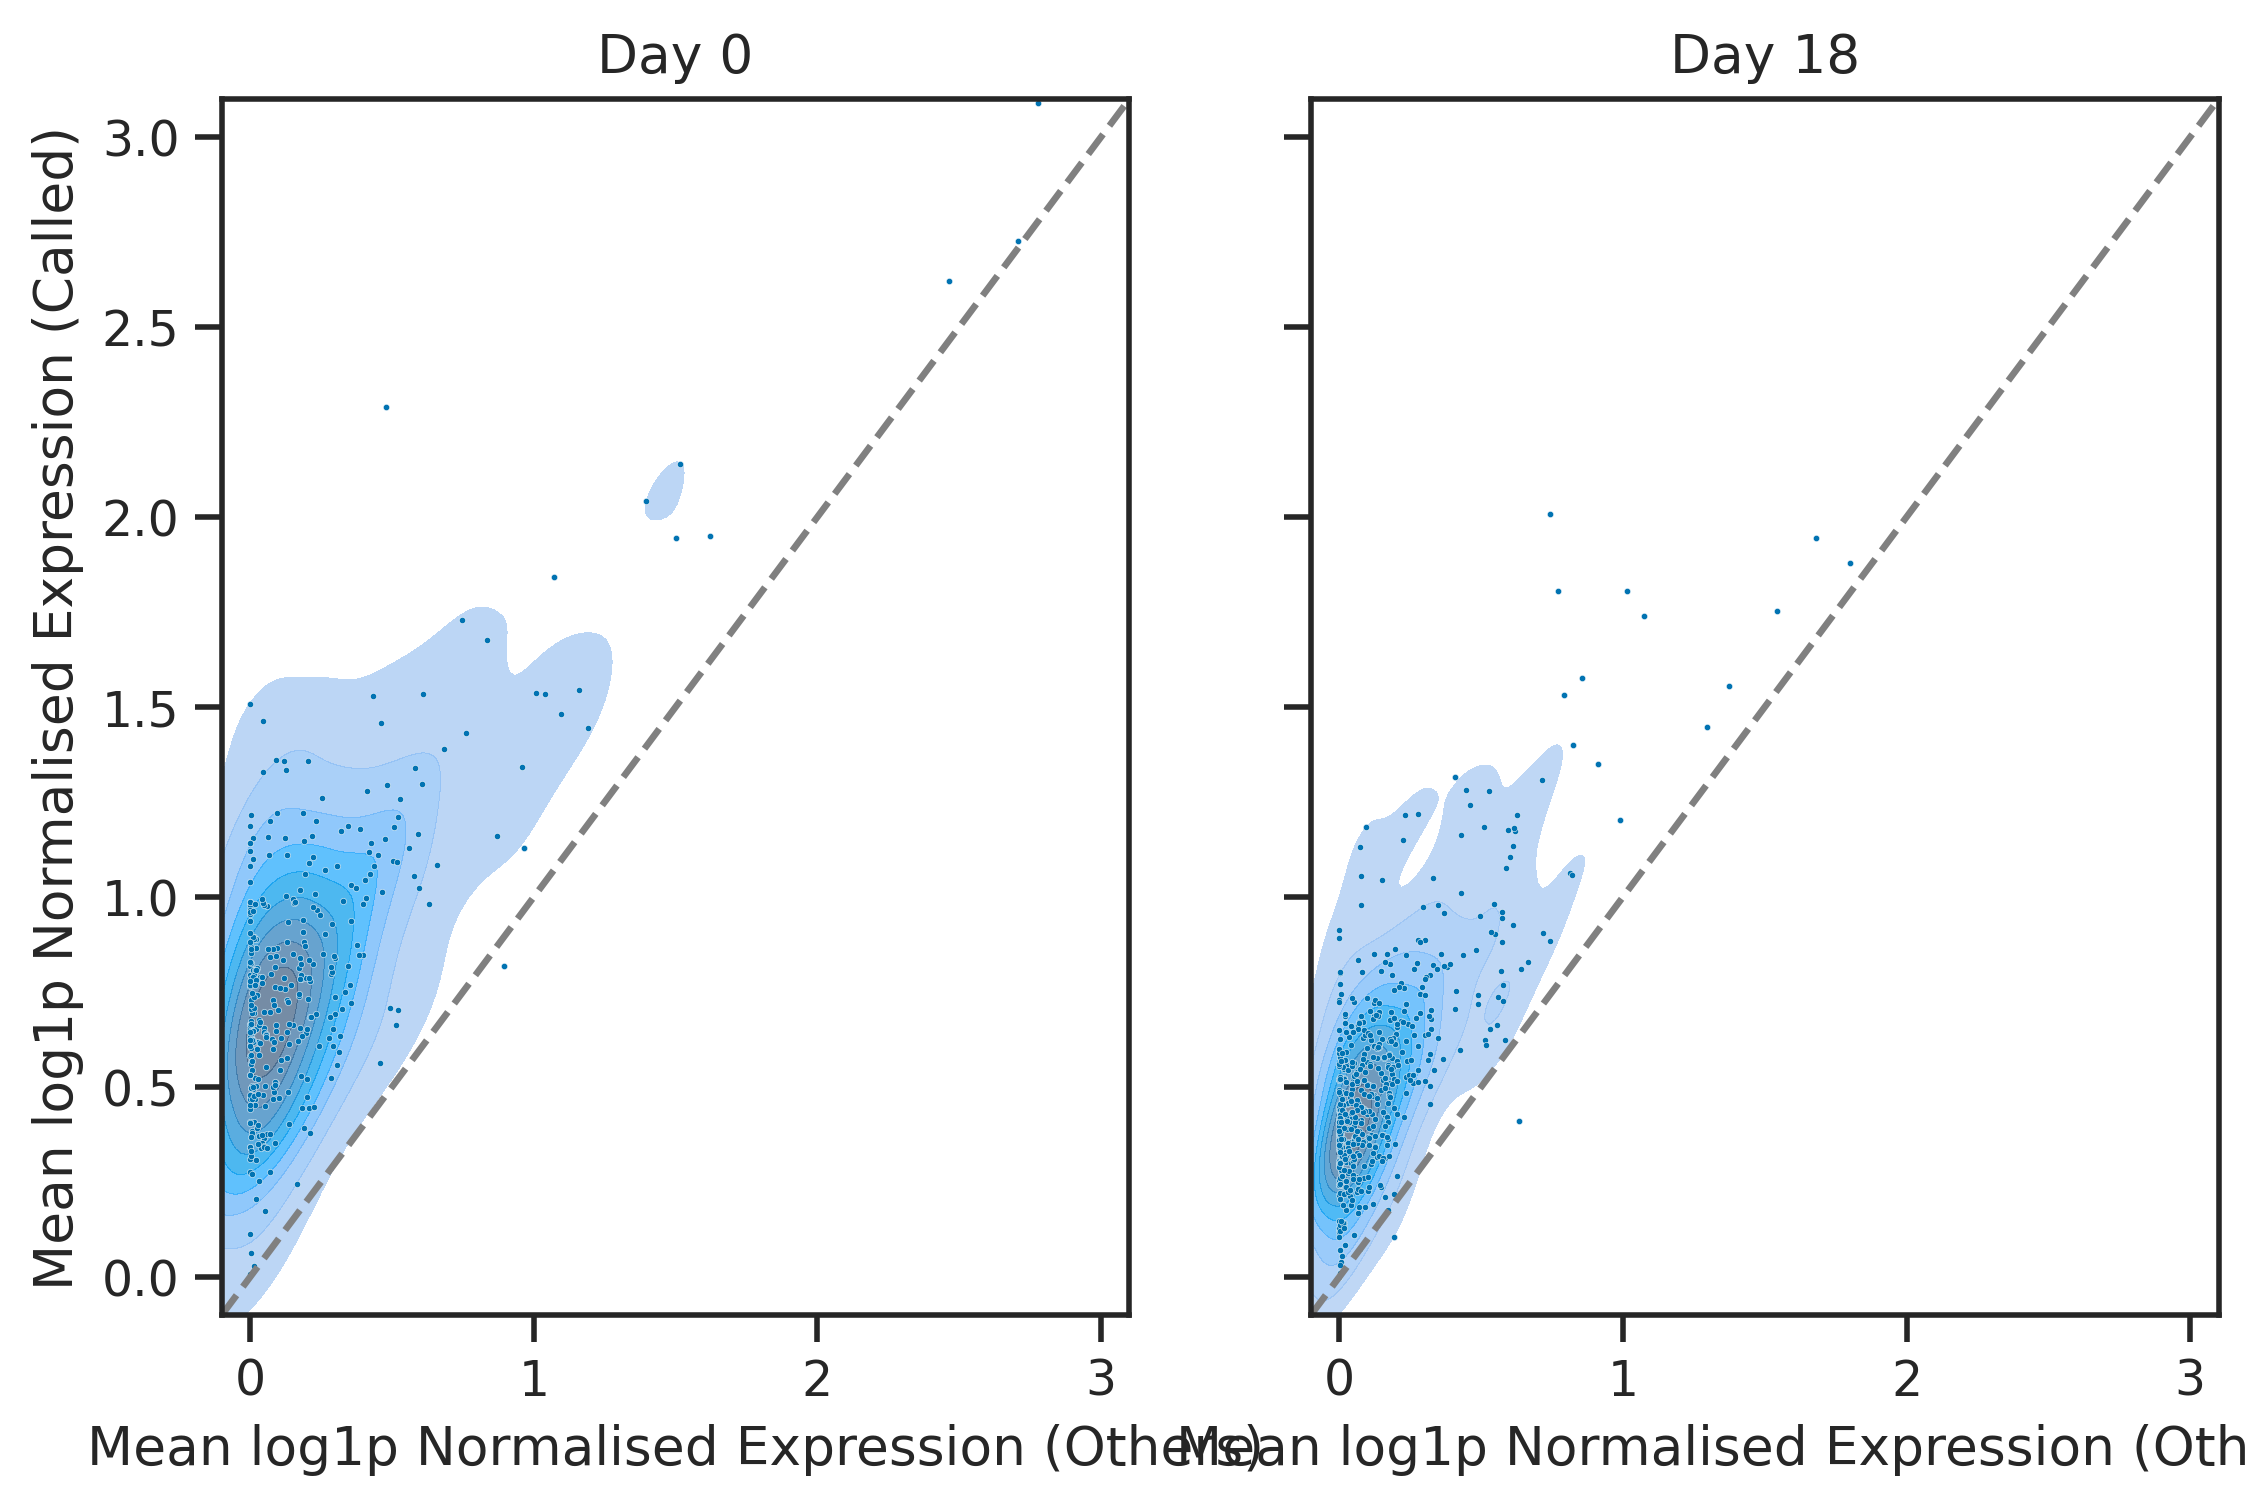

In [23]:
# reshape
df_long = pd.concat([
    df_combined[["mean_exp_called_d0", "mean_exp_others_d0"]]
    .rename(columns={
        "mean_exp_called_d0": "mean_exp_called",
        "mean_exp_others_d0": "mean_exp_others"
    })
    .assign(day="d0"),

    df_combined[["mean_exp_called_d18", "mean_exp_others_d18"]]
    .rename(columns={
        "mean_exp_called_d18": "mean_exp_called",
        "mean_exp_others_d18": "mean_exp_others"
    })
    .assign(day="d18")
], ignore_index=True)

# plot
sb.set_theme(style="ticks")

import seaborn as sb
import matplotlib.pyplot as plt

sb.set_theme(style="ticks")
palette = sb.color_palette("colorblind")

fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharex=True, sharey=True)

plot_specs = {
    "d0": {
        "x": "mean_exp_others_d0",
        "y": "mean_exp_called_d0",
        "title": "Day 0"
    },
    "d18": {
        "x": "mean_exp_others_d18",
        "y": "mean_exp_called_d18",
        "title": "Day 18"
    }
}

for ax, spec in zip(axes, plot_specs.values()):
    sb.kdeplot(
        data=df_combined,
        x=spec["x"],
        y=spec["y"],
        levels=10,
        fill=True,
        alpha=0.7,
        color=palette[0],
        ax=ax
    )

    sb.scatterplot(
        data=df_combined,
        x=spec["x"],
        y=spec["y"],
        s=2,
        alpha=1,
        color=palette[0],
        ax=ax
    )

    ax.axline((0, 0), slope=1, linestyle="--", color="grey")
    ax.set_title(spec["title"])
    ax.set_xlabel("Mean log1p Normalised Expression (Others)")
    ax.set_ylabel("Mean log1p Normalised Expression (Called)")

    
    ax.set_xlim(-0.1, 3.1)
    ax.set_ylim(-0.1, 3.1)

plt.savefig(fig_path+"mean_exp_tf_called_vs_others_separate.pdf", bbox_inches='tight')

### Plot the expression distribution

In [24]:
df_plot = pd.DataFrame({'mean_exp_called':list(df_d0['mean_exp_called'])+list(df_d0['mean_exp_others'])+list(df_d18['mean_exp_called'])+list(df_d18['mean_exp_others']),
                           'days':['d0']*df_d0.shape[0]*2+['d18']*df_d18.shape[0]*2,
                       'TF_called':['called']*df_d0.shape[0] + ['others']*df_d0.shape[0] + ['called']*df_d0.shape[0] + ['others']*df_d0.shape[0]
                       })

In [25]:
df_plot['day_tf'] = df_plot['days'].astype('str') +'_' + df_plot['TF_called'].astype('str')

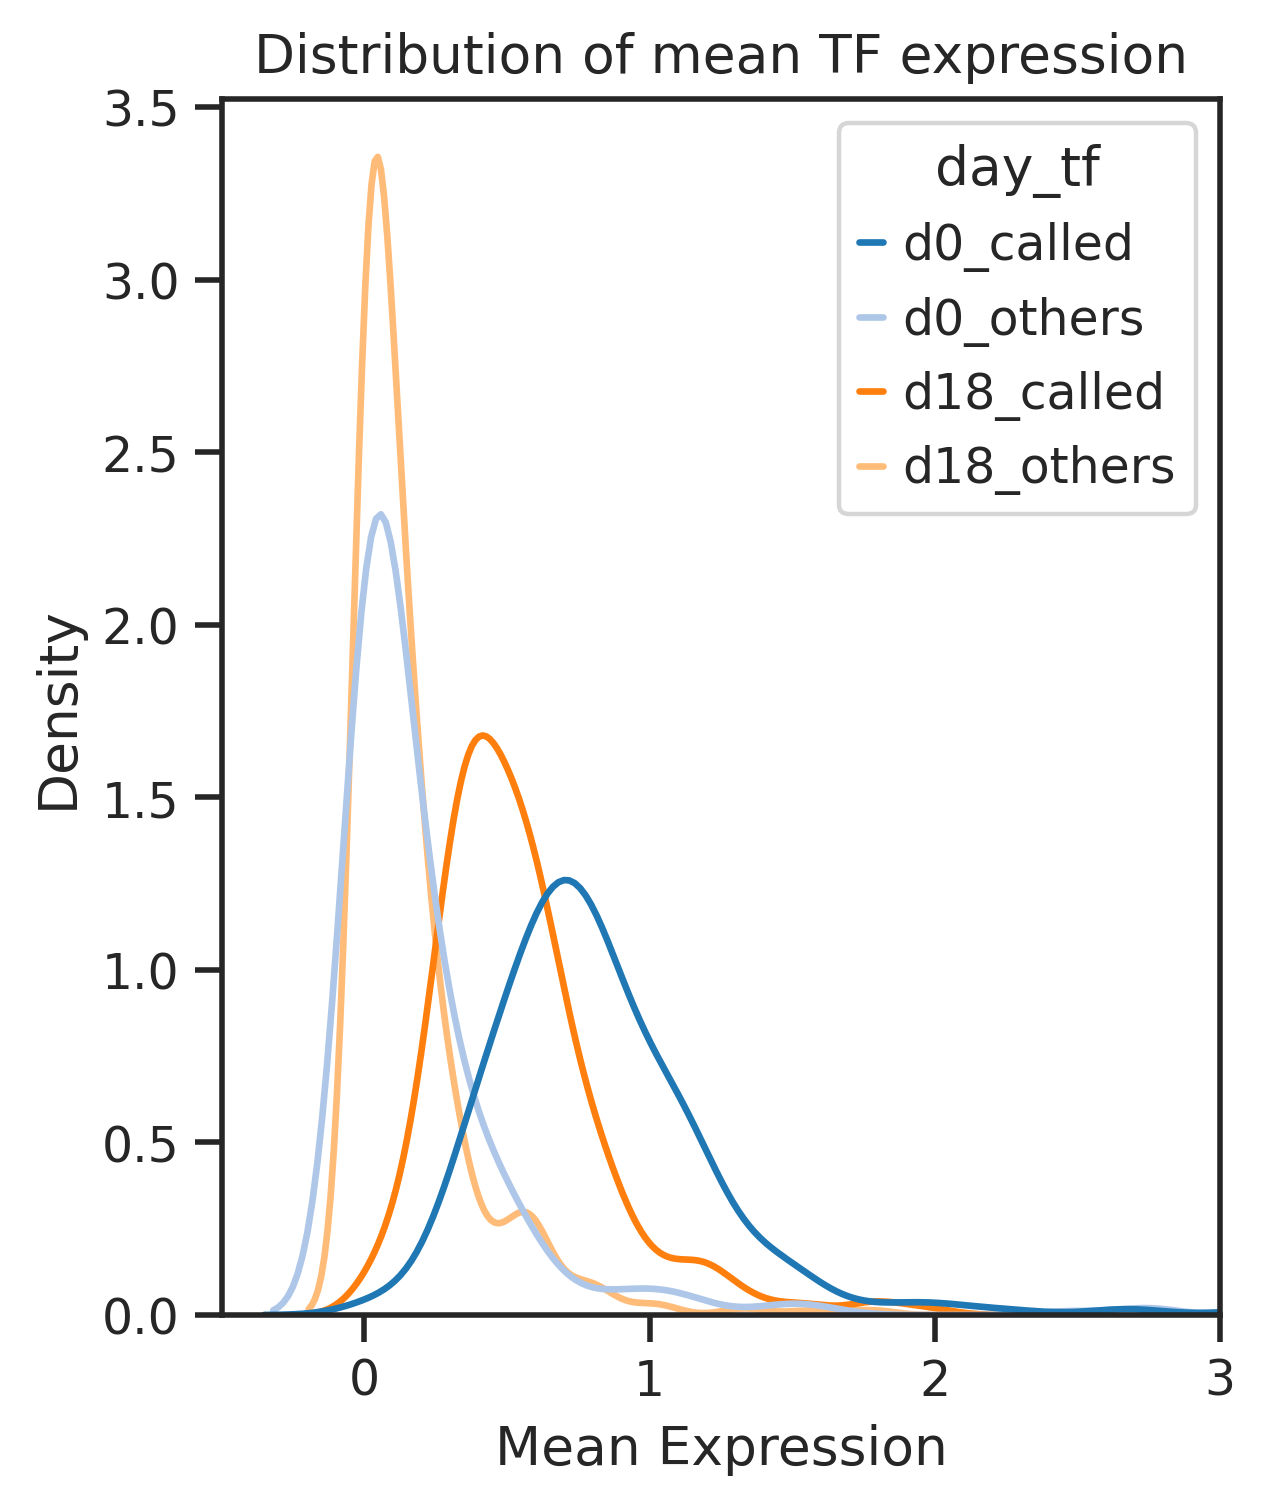

In [26]:
sb.set_theme(style='ticks')
fig, ax = plt.subplots(figsize=(4,5))
sb.kdeplot(data=df_plot, x="mean_exp_called", hue="day_tf", common_norm = False, palette="tab20")

plt.title("Distribution of mean TF expression")
plt.xlabel("Mean Expression")
plt.xlim(-0.5, 3)

plt.savefig(fig_path+"mean_exp_tf_called_vs_others.pdf", bbox_inches='tight')

## Heatmap of TF calling vs expression

In [47]:
day = '18'
adata_select = adata_d18

In [48]:
c = Counter(adata_select.obs.loc[~adata_select.obs['TF_calling'].isna(),'TF_calling'])
df = pd.DataFrame(c.items(), columns=['item', 'count'])

In [49]:
df = df.sort_values(by='count', ascending=False)
df.head(10)

,item,count
6,MULTIHIT,3492
28,FOXR1,1512
23,WWTR1,1369
9,FOSL2,1355
16,ZBTB9,992
1,EGR4,958
5,ESRRB,604
7,IRF5,563
39,NR1I2,395
20,ZNF213,345


In [50]:
# remove MULTIHIT
df = df.loc[df['item']!='MULTIHIT',:]

Text(0.5, 0, 'number of cells')

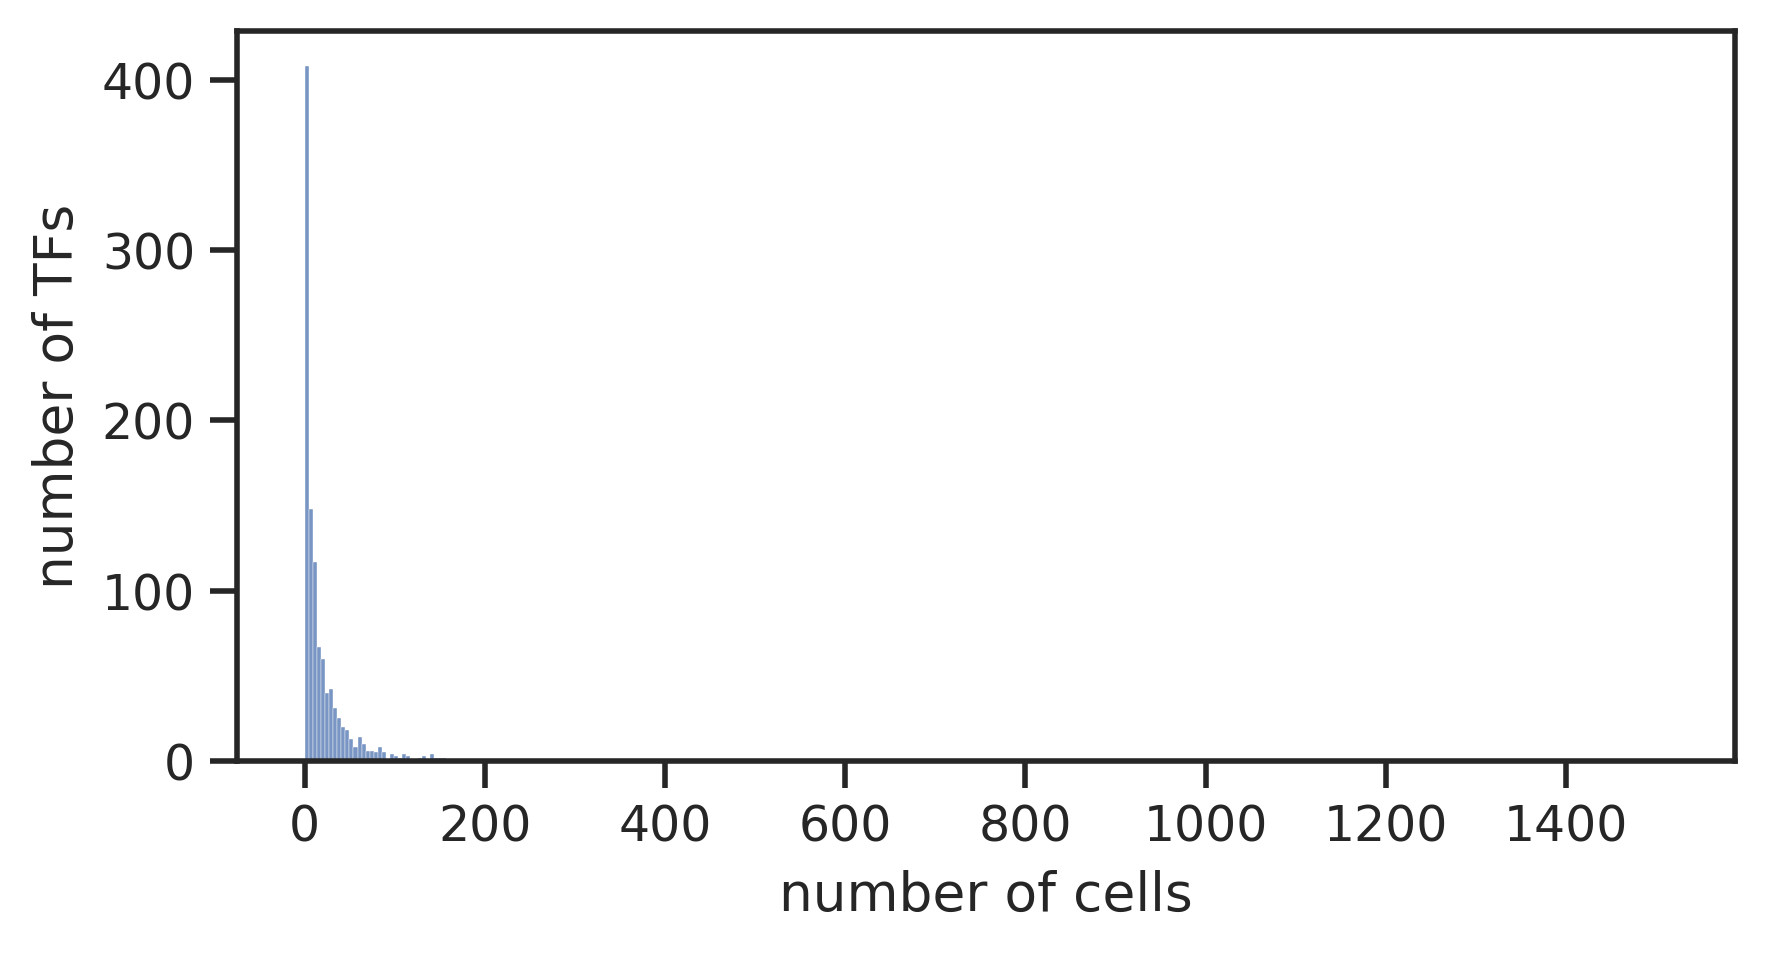

In [51]:
plt.figure(figsize=(6, 3))

ax = sb.histplot(df, x='count')
#ax.set_yscale('log')
#ax.set_xlim(0, 500)
ax.set_ylabel('number of TFs')
ax.set_xlabel('number of cells')

In [52]:
# remove TFs with < 10 cells
df = df.loc[df['count']>9,:]
# only keep TFs in adata_select.var_names
df = df.loc[df['item'].isin(adata_select.var_names)]
df = df.sort_values(by='count', ascending=False)
tf_list = list(df['item'])

In [53]:
tf_exp = pd.DataFrame(index = tf_list, columns = tf_list)
for tf in tf_list:
    select1 = adata_select.obs['TF_calling'] == tf
    tf_exp.loc[tf,:] = np.mean(adata_select[select1.values, tf_list].X, axis=0)
    
tf_exp_numeric = tf_exp.astype(float)
#tf_exp_scaled = tf_exp_numeric / tf_exp_numeric.max() # scale gene expression by column i.e. by gene

In [54]:
tf_exp_numeric.shape

(549, 549)

In [55]:
# scale to maximum of 1 per column 
tf_scaled = tf_exp_numeric / tf_exp_numeric.max()

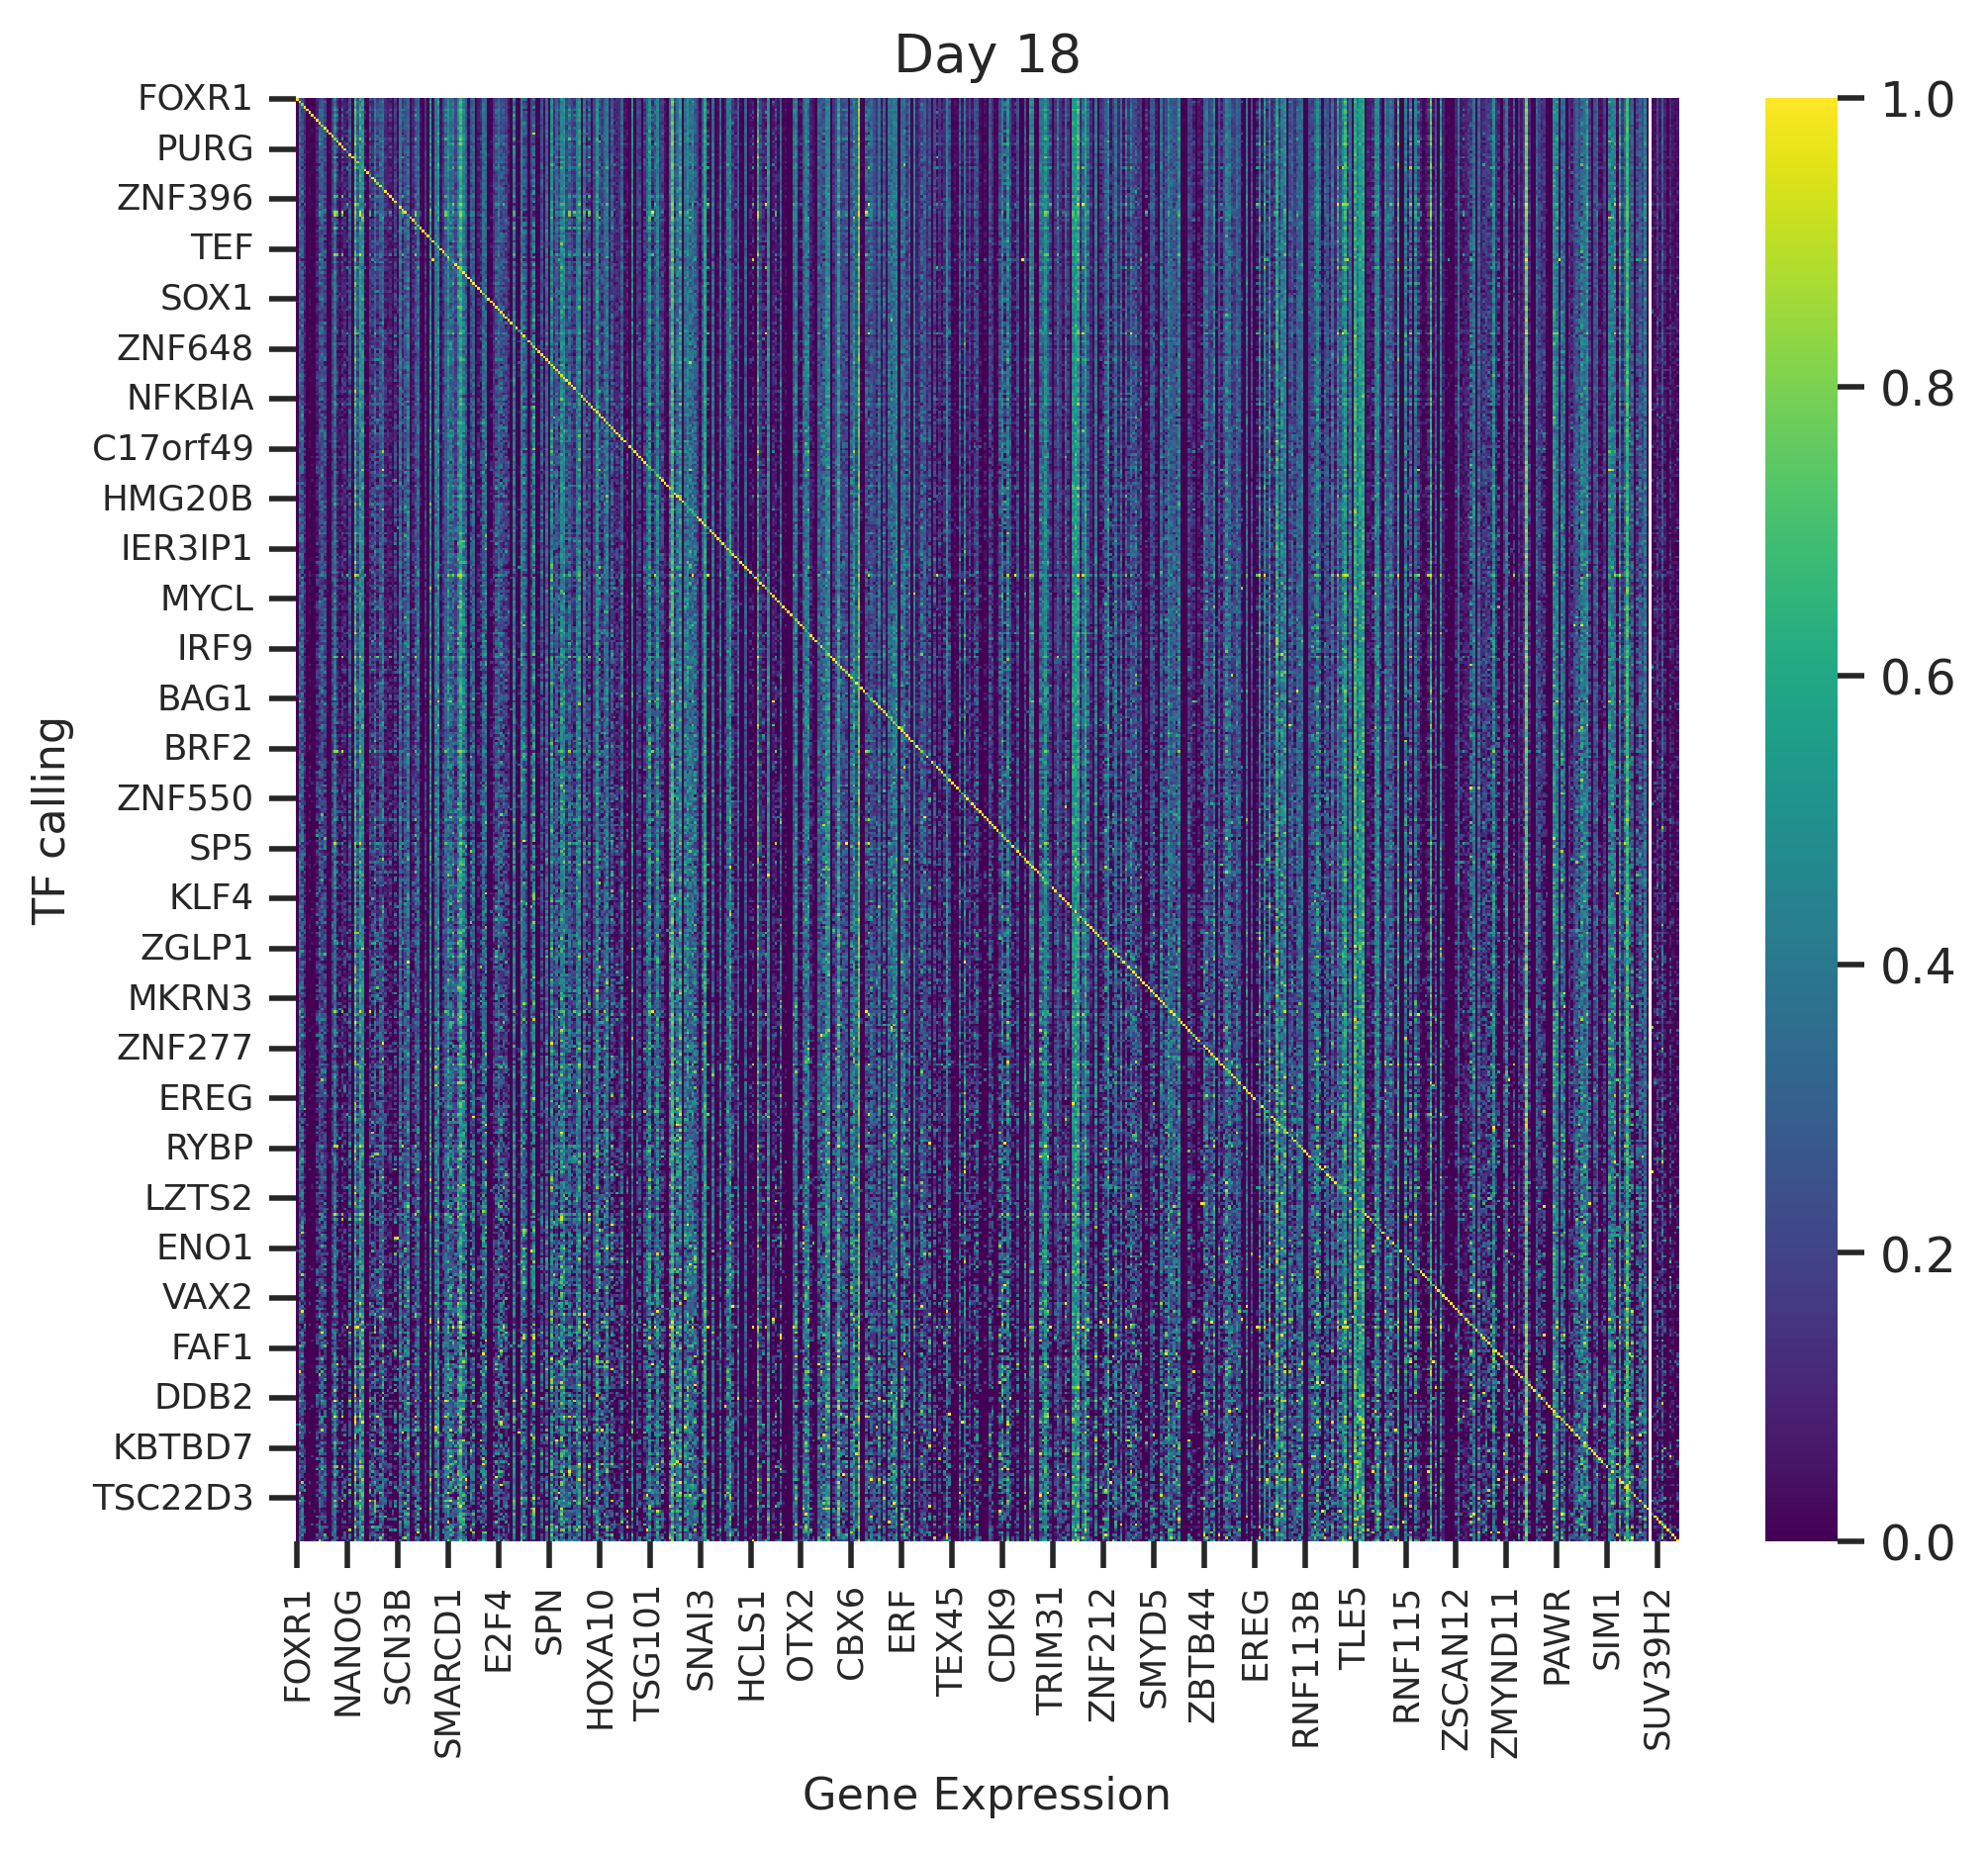

In [56]:
sb.set_theme(style='ticks')
plt.figure(figsize=(7, 6))  # Set figure size

ax = sb.heatmap(tf_scaled, cmap='viridis', cbar=True, linewidths=0)  # Remove background grid with linewidths=0

# Change tick label size
ax.set_xticklabels(ax.get_xticklabels(), fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)

plt.title("Day "+ day)
plt.ylabel("TF calling", fontsize=10)
plt.xlabel("Gene Expression", fontsize=10)

plt.savefig(fig_path+day+'_TF_exp_heatmap.pdf',bbox_inches='tight')

In [57]:
# Create a Series to store the diagonal ranks
diagonal_ranks = pd.Series(index=tf_exp_numeric.index, dtype=float)

for row in tf_exp_numeric.index:
    row_values = tf_exp_numeric.loc[row]
    diagonal_value = row_values[row]  # Diagonal entry
    rank = row_values.rank(ascending=False)  # Highest value gets rank 1
    diagonal_ranks[row] = rank[row]
    
diagonal_ranks = diagonal_ranks/len(diagonal_ranks)
diagonal_ranks.to_csv('csv/'+day+'_diagonal_ranks.csv')

In [58]:
d0 = pd.read_csv('csv/0_diagonal_ranks.csv', index_col=0)
d18 = pd.read_csv('csv/18_diagonal_ranks.csv', index_col=0)

In [59]:
df_combine = pd.DataFrame({'rank_percentile': list(d0['0']*100) + list(d18['0']*100), 
                          'day': ['D0']*d0.shape[0]+['D18']*d18.shape[0]})

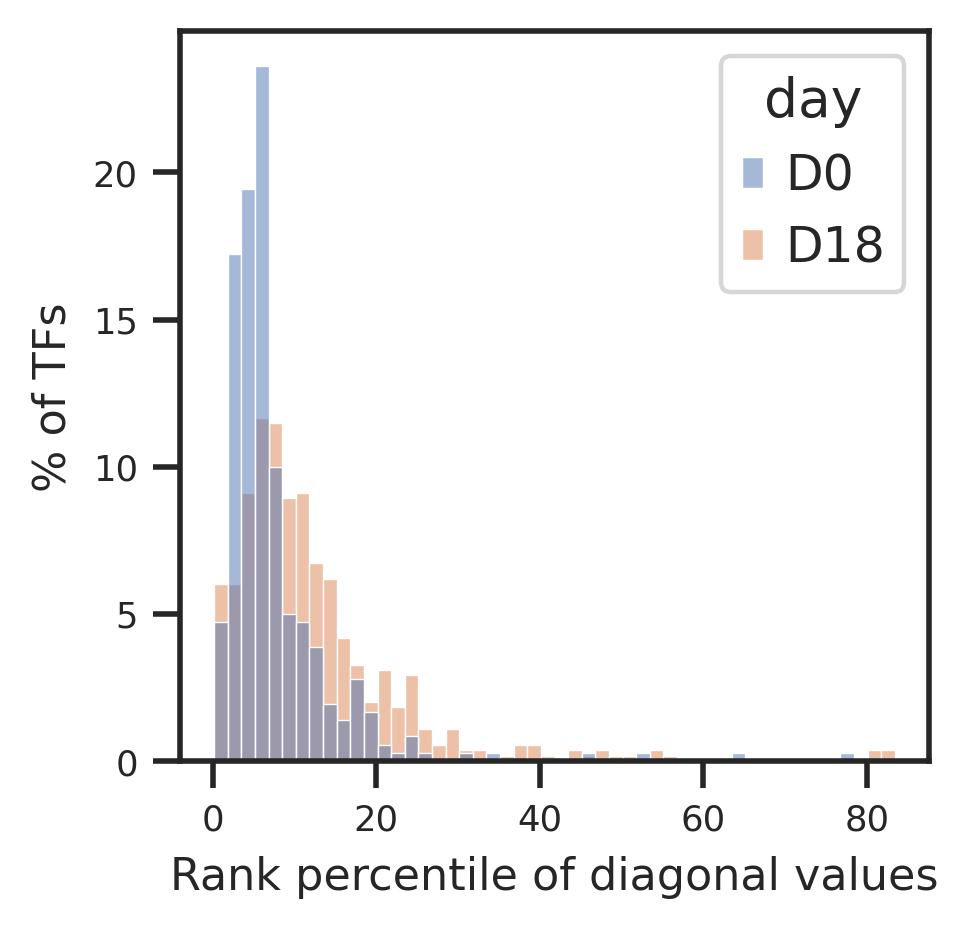

In [60]:
sb.set_theme(style='ticks')
plt.figure(figsize=(3, 3))  

s = sb.histplot(df_combine, x= 'rank_percentile', hue='day', stat = 'percent', common_norm = False)
s.set_xlabel('Rank percentile of diagonal values', fontsize=10)
s.set_ylabel('% of TFs', fontsize=10)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.savefig(fig_path+'diagonal_ranks.pdf',bbox_inches='tight')

# Demonstrate that TF has changed the transcriptome

### Use mean connectivities

In [10]:
from scipy.stats import mannwhitneyu

In [62]:
day_select = 18
adata_select = adata[adata.obs['HSC_days']==day_select]

In [63]:
# recalculated neighbourhood and UMAP
sc.pp.neighbors(adata_select, use_rep = 'X_scVI', random_state=1712)
sc.tl.umap(adata_select,random_state=1712)

In [64]:
tf_list = [tf for tf in adata_select.obs['TF_calling'].cat.categories if tf in adata.var_names]

In [80]:
conn = adata_select.obsp["connectivities"].tocsr()

# compute for each TF, the average pairwise connectivities
df_distance = pd.DataFrame(index = tf_list, columns = ['mean_connectivity','connectivity_background','n_cells'])

for tf in tf_list:
    select = np.array(adata_select.obs['TF_calling']==tf)
    cells = np.where(select)[0]
    df_distance.loc[tf, 'n_cells']=sum(select)
    
    if sum(select)>19: # at least 20 cells
        # 1. Compute mean within-group connectivity
        subgraph = conn[cells[:, None], cells]  
        df_distance.loc[tf, 'mean_connectivity'] = subgraph.sum() / (len(cells) * (len(cells) - 1))  # exclude self-connections
        
        # 2. Randomly sample the same number of cells, and compute mean within-group connectivity
        random_cells = np.random.choice(range(adata_select.shape[0]), size=sum(select), replace=False)
        subgraph_bkg = conn[random_cells[:, None], random_cells]  
        df_distance.loc[tf, 'connectivity_background'] = subgraph_bkg.sum() / (len(random_cells) * (len(random_cells) - 1))  # exclude self-connections
        
df_distance.to_csv('csv/tf_scvi_15neighbour_connectivity_d'+str(day_select)+'.csv')

In [6]:
day_select = 18
df_distance = pd.read_csv('csv/tf_scvi_15neighbour_connectivity_d'+str(day_select)+'.csv', index_col=0)

In [8]:
plt.rcParams["figure.figsize"] = [4,4]

In [11]:
# melt to long form for plotting
df_long = df_distance.loc[~df_distance['mean_connectivity'].isna(),['mean_connectivity','connectivity_background']].melt(var_name='metric', value_name='value')

# wilcoxon rank sum testing 
x = df_long.loc[df_long['metric']=='mean_connectivity','value']
y = df_long.loc[df_long['metric']=='connectivity_background','value']
stat, p = mannwhitneyu(list(x), list(y), alternative='two-sided')
print(f"Mann–Whitney U statistic: {stat}, p-value: {p}")

Mann–Whitney U statistic: 106207.5, p-value: 9.631566644349503e-71


In [12]:
df_distance.sort_values("mean_connectivity", ascending=False).head(20)

,mean_connectivity,connectivity_background,n_cells
AATF,0.037156,0.000000,32
SOX2,0.030253,0.000254,38
KLF2,0.029550,0.000000,50
OTP,0.029291,0.000000,23
THAP10,0.029099,0.000000,26
SMAD7,0.024304,0.000274,83
FOS,0.022294,0.000110,146
KLF4,0.021549,0.000000,24
OTX2,0.021547,0.000250,35
NR4A3,0.020659,0.000000,47


In [78]:
df_distance.loc['NR4A2',:]

mean_connectivity            0.005564
connectivity_background      0.000042
n_cells                    104.000000
Name: NR4A2, dtype: float64

In [79]:
df_distance.loc['NR4A3',:]

mean_connectivity           0.020659
connectivity_background     0.000000
n_cells                    47.000000
Name: NR4A3, dtype: float64

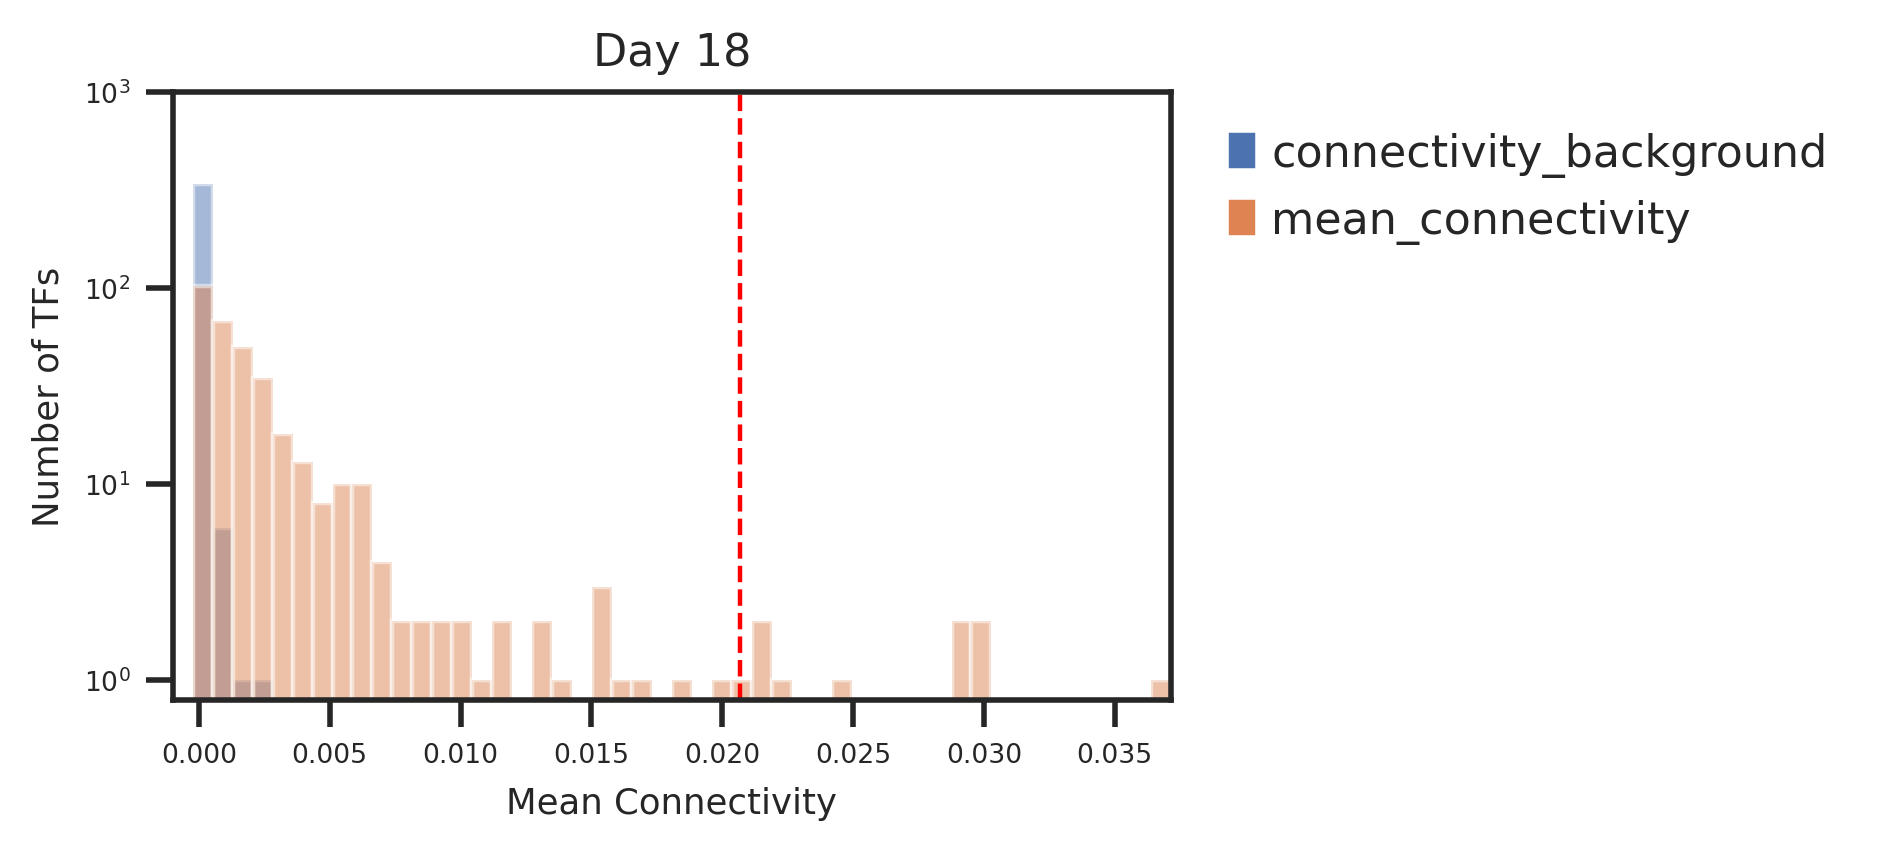

In [13]:
from matplotlib.patches import Patch
# -----------------------------
# settings
# -----------------------------
sb.set_theme(style='ticks')
fig, ax = plt.subplots(figsize=(4, 2.5))

x_min, x_max = -0.001, np.max(df_long['value'])
n_bins = 50
bins = np.linspace(x_min, x_max, n_bins + 1)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
bin_width = bins[1] - bins[0]

# -----------------------------
# manual histogram counts
# -----------------------------
plot_list = []

for metric_name, subdf in df_long.groupby("metric"):
    values = subdf["value"].dropna().values

    counts, edges = np.histogram(values, bins=bins)

    hist_df = pd.DataFrame({
        "metric": metric_name,
        "bin_left": edges[:-1],
        "bin_right": edges[1:],
        "bin_center": bin_centers,
        "count": counts
    })

    # remove zero bins so log scale works cleanly
    hist_df = hist_df[hist_df["count"] > 0]
    
    # log10 transform
    hist_df["log10_count"] = np.log10(hist_df["count"]) +0.1

    plot_list.append(hist_df)

hist_counts = pd.concat(plot_list, ignore_index=True)

# -----------------------------
# plot manually
# -----------------------------
palette = dict(
    zip(
        hist_counts["metric"].unique(),
        sb.color_palette(n_colors=hist_counts["metric"].nunique())
    )
)

for metric_name, subdf in hist_counts.groupby("metric"):
    ax.bar(
        subdf["bin_center"],
        subdf["log10_count"],
        width=bin_width,
        alpha=0.5,
        color=palette[metric_name],
        label=metric_name,
        align="center"
    )

# -----------------------------
# labels and axes
# -----------------------------
ax.set_title("Day " + str(day_select), fontsize=10)
ax.set_xlabel("Mean Connectivity", fontsize=8)
ax.set_ylabel("Number of TFs", fontsize=8)

ax.tick_params(axis='x', labelsize=6)
ax.tick_params(axis='y', labelsize=6)

ax.set_xlim(x_min, x_max)
ax.set_ylim(0, None)

# revert back ytick labels so that 0.1=1
yticks = np.arange(0.1, hist_counts["log10_count"].max() + 1, 1)
ytick_labels = [r"$10^{{{}}}$".format(int(y - 0.1)) for y in yticks]
ax.set_yticks(yticks)
ax.set_yticklabels(ytick_labels)

# -----------------------------
# vertical line for SMAD7
# -----------------------------
gene = 'NR4A3'
gene_connec = df_distance.loc[gene, 'mean_connectivity']
ax.axvline(x=gene_connec, color='red', linestyle='--', linewidth=1)

# -----------------------------
# custom legend labels
# -----------------------------
legend_map = {
    'actual_connectivity': 'actual_connectivity',
    'background_connectivity': 'background_connectivity'
}

legend_handles = [
    Patch(color=palette[m], label=legend_map.get(m, m))
    for m in palette
]

ax.legend(
    handles=legend_handles,
    title='',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    fontsize='small',
    frameon=False
)

plt.savefig(fig_path + str(day_select) + '_15neighbor_connectivity.pdf',bbox_inches='tight')
plt.show()